# Telco — Autoencoder

Unsupervised AE trained **only on non-churned clients** to learn a compact
representation of the **19 Telco features** (4 numeric + 15 categorical).  
Bottleneck sweep: `z_dim ∈ {8, 16, 32}`.  
Outputs go to `src/w4_autoencoders/checkpoints/` and `src/w4_autoencoders/runs/`.

## 0. Setup

In [1]:
import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Notebook lives at src/w4_autoencoders/; resolve project root two levels up
_w4_root = Path().resolve()
if _w4_root.name != 'w4_autoencoders':
    # running from a different CWD — adjust as needed
    _w4_root = Path(__file__).resolve().parent if '__file__' in dir() else Path().resolve()

if str(_w4_root) not in sys.path:
    sys.path.insert(0, str(_w4_root))

from constants import SEED, Z_DIMS, CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR
from autoencoder.data_loader  import load_telco_data, filter_normal
from autoencoder.preprocessor import TabularPreprocessor
from autoencoder.autoencoder_ae import AEConfig, Autoencoder
from train.train_ae    import set_seed, build_loader, AETrainer, save_checkpoint, load_checkpoint
from evaluate.evaluate_ae import ReconstructionEvaluator

RUNS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
set_seed(SEED)
print(f'device: {DEVICE}  |  z_dims: {Z_DIMS}')

device: cpu  |  z_dims: (8, 16, 32)


## 1. Load Data

In [2]:
df, y_all, features, categorical, numeric, split = load_telco_data()
fit_normal, stop_normal = filter_normal(split, y_all)

print(f'Total rows:            {len(df):>7,}')
print(f'Churn rate (all):      {y_all.mean():.4f}')
print()
print(f'fit  (train) set:      {len(split["fit"]):>7,}  (churn rate: {y_all[split["fit"]].mean():.4f})')
print(f'stop (val)   set:      {len(split["stop"]):>7,}  (churn rate: {y_all[split["stop"]].mean():.4f})')
print(f'test         set:      {len(split["test"]):>7,}  (churn rate: {y_all[split["test"]].mean():.4f})')
print()
print(f'fit_normal  (AE train): {len(fit_normal):>7,}')
print(f'stop_normal (AE val):   {len(stop_normal):>7,}')
print()
print(f'Numeric features ({len(numeric)}):     {numeric}')
print(f'Categorical features ({len(categorical)}): {categorical}')

Total rows:              7,043
Churn rate (all):      0.2654

fit  (train) set:        4,930  (churn rate: 0.2653)
stop (val)   set:        1,056  (churn rate: 0.2652)
test         set:        1,057  (churn rate: 0.2658)

fit_normal  (AE train):   3,622
stop_normal (AE val):       776

Numeric features (4):     ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 2. Preprocessor

Fitted exclusively on `fit_normal` (non-churned training clients).  
Steps: impute → signed-log1p (skewed cols) → quantile clip → standardize; vocabulary for categoricals.

In [3]:
prep = TabularPreprocessor(numeric, categorical)
prep.fit(df.iloc[fit_normal])

print(f'numeric_dim      = {prep.numeric_dim}')
print(f'n_const cols     = {prep.n_const}  (excluded from model input)')
print(f'cat_cardinalities= {prep.cat_cardinalities}')
print(f'input_dim        = {prep.input_dim}  (numeric + sum(cat_cardinalities))')

x_num_fit,  x_cat_fit  = prep.transform(df.iloc[fit_normal])
x_num_stop, x_cat_stop = prep.transform(df.iloc[stop_normal])
x_num_test, x_cat_test = prep.transform(df.iloc[split['test']])
y_test = y_all[split['test']]

print(f'\nx_num_fit  shape: {x_num_fit.shape}')
print(f'x_num_test shape: {x_num_test.shape}')

numeric_dim      = 4
n_const cols     = 0  (excluded from model input)
cat_cardinalities= (3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 5)
input_dim        = 60  (numeric + sum(cat_cardinalities))

x_num_fit  shape: torch.Size([3622, 4])
x_num_test shape: torch.Size([1057, 4])


### 2a. Skewness inspection

In [4]:
skew_info = pd.DataFrame({
    'feature': numeric,
    'log_transformed': prep._log_mask,
    'binary': prep._binary_mask,
    'constant': prep._const_mask,
})
print(skew_info.to_string(index=False))

       feature  log_transformed  binary  constant
 SeniorCitizen             True    True     False
        tenure            False   False     False
MonthlyCharges            False   False     False
  TotalCharges            False   False     False


## 3. z_dim Sweep

Train one AE per bottleneck size. Saves checkpoint + history CSV per run.

In [5]:
results: dict = {}

for z in Z_DIMS:
    print(f'\n' + '='*55)
    print(f'  Training AE  z_dim={z}')
    print('='*55)

    config = AEConfig(
        numeric_dim=prep.numeric_dim,
        cat_cardinalities=prep.cat_cardinalities,
        z_dim=z,
        seed=SEED,
    )
    set_seed(SEED)
    model = Autoencoder(config).to(DEVICE)

    train_loader = build_loader(x_num_fit,  x_cat_fit,  config.batch_size, shuffle=True)
    val_loader   = build_loader(x_num_stop, x_cat_stop, config.batch_size, shuffle=False)

    trainer = AETrainer(model, config, DEVICE)
    history = trainer.fit(train_loader, val_loader)

    ckpt_path = CHECKPOINTS_DIR / f'ae_z{z}.pt'
    save_checkpoint(ckpt_path, model, config, prep, history, trainer.best_epoch)
    history.to_csv(RUNS_DIR / f'ae_z{z}_history.csv', index=False)
    results[z] = history
    print(f'  saved {ckpt_path.name}  (best epoch {trainer.best_epoch})')


  Training AE  z_dim=8


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  train=2.28880  val=2.26709  (num=1.00252  cat=1.26456)
  epoch   5  train=1.14620  val=1.08235  (num=0.35882  cat=0.72353)
  epoch  10  train=0.60524  val=0.58886  (num=0.04057  cat=0.54829)
  epoch  15  train=0.52810  val=0.51795  (num=0.01247  cat=0.50548)
  epoch  20  train=0.50893  val=0.50085  (num=0.01317  cat=0.48768)
  epoch  25  train=0.49352  val=0.48297  (num=0.01547  cat=0.46750)
  epoch  30  train=0.45192  val=0.44226  (num=0.01440  cat=0.42786)
  epoch  35  train=0.43153  val=0.42284  (num=0.01304  cat=0.40980)
  epoch  40  train=0.41222  val=0.40841  (num=0.01391  cat=0.39449)
  epoch  45  train=0.39082  val=0.38707  (num=0.01113  cat=0.37594)
  epoch  50  train=0.37852  val=0.37448  (num=0.00955  cat=0.36493)
  saved ae_z8.pt  (best epoch 50)

  Training AE  z_dim=16


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  train=2.27651  val=2.24854  (num=0.98207  cat=1.26647)
  epoch   5  train=0.96469  val=0.84298  (num=0.12008  cat=0.72289)
  epoch  10  train=0.55261  val=0.54265  (num=0.01451  cat=0.52814)
  epoch  15  train=0.52161  val=0.51232  (num=0.01512  cat=0.49720)
  epoch  20  train=0.50313  val=0.49302  (num=0.01505  cat=0.47797)
  epoch  25  train=0.47439  val=0.46336  (num=0.01147  cat=0.45189)
  epoch  30  train=0.44714  val=0.43953  (num=0.00855  cat=0.43098)
  epoch  35  train=0.43728  val=0.42968  (num=0.01246  cat=0.41721)
  epoch  40  train=0.41016  val=0.40278  (num=0.00898  cat=0.39380)
  epoch  45  train=0.38000  val=0.37456  (num=0.00978  cat=0.36478)
  epoch  50  train=0.36220  val=0.36023  (num=0.00826  cat=0.35197)
  saved ae_z16.pt  (best epoch 50)

  Training AE  z_dim=32
  epoch   1  train=2.25773  val=2.22324  (num=0.96887  cat=1.25436)


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   5  train=0.93430  val=0.88789  (num=0.22991  cat=0.65798)
  epoch  10  train=0.55909  val=0.56342  (num=0.03344  cat=0.52997)
  epoch  15  train=0.52508  val=0.51814  (num=0.01686  cat=0.50128)
  epoch  20  train=0.50519  val=0.49499  (num=0.01656  cat=0.47843)
  epoch  25  train=0.48071  val=0.47189  (num=0.01289  cat=0.45900)
  epoch  30  train=0.45954  val=0.44181  (num=0.01035  cat=0.43145)
  epoch  35  train=0.43337  val=0.41999  (num=0.01445  cat=0.40554)
  epoch  40  train=0.41368  val=0.39907  (num=0.01016  cat=0.38891)
  epoch  45  train=0.39495  val=0.37693  (num=0.01098  cat=0.36595)
  epoch  50  train=0.37880  val=0.36272  (num=0.01084  cat=0.35188)
  saved ae_z32.pt  (best epoch 50)


## 4. Compare z_dim

In [6]:
summary_rows = []
for z, hist in results.items():
    best = hist.loc[hist['val_loss'].idxmin()]
    summary_rows.append({
        'z_dim':      z,
        'best_epoch': int(best['epoch']),
        'val_loss':   round(float(best['val_loss']), 6),
        'val_num':    round(float(best['val_num']),  6),
        'val_cat':    round(float(best['val_cat']),  6),
    })
summary_df = pd.DataFrame(summary_rows).set_index('z_dim')
print(summary_df.to_string())

       best_epoch  val_loss   val_num   val_cat
z_dim                                          
8              50  0.374477  0.009545  0.364932
16             50  0.360231  0.008264  0.351967
32             50  0.362719  0.010837  0.351882


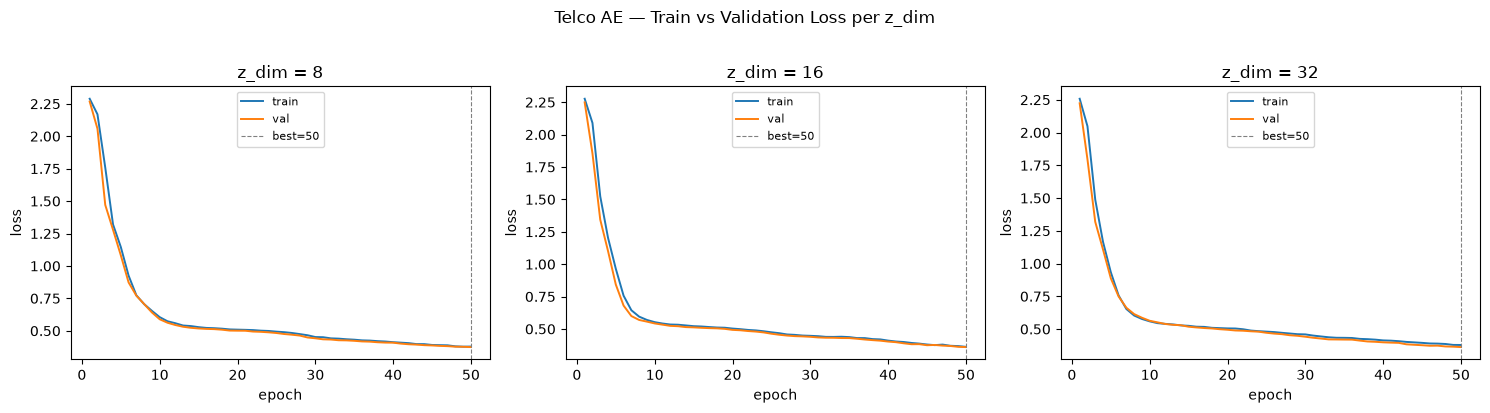

In [7]:
fig, axes = plt.subplots(1, len(Z_DIMS), figsize=(15, 4), sharey=False)
for ax, (z, hist) in zip(axes, results.items()):
    ax.plot(hist['epoch'], hist['train_loss'], label='train', linewidth=1.4)
    ax.plot(hist['epoch'], hist['val_loss'],   label='val',   linewidth=1.4)
    best_ep = int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])
    ax.axvline(best_ep, color='gray', linestyle='--', linewidth=0.8, label=f'best={best_ep}')
    ax.set_title(f'z_dim = {z}')
    ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend(fontsize=8)
plt.suptitle('Telco AE — Train vs Validation Loss per z_dim', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Select Best z

**Trade-off**: smaller `z` compresses more (useful for anomaly detection later) but
sacrifices reconstruction quality. Inspect the summary table and adjust `BEST_Z`.

In [8]:
BEST_Z = 16  # adjust after inspecting the summary table

shutil.copy(CHECKPOINTS_DIR / f'ae_z{BEST_Z}.pt', CHECKPOINTS_DIR / 'ae_best.pt')
print(f'Best checkpoint: z_dim={BEST_Z}  ->  checkpoints/ae_best.pt')

Best checkpoint: z_dim=16  ->  checkpoints/ae_best.pt


## 6. Evaluate on Test Set

In [9]:
model_best, config_best, prep_best, history_best, best_ep = load_checkpoint(
    CHECKPOINTS_DIR / 'ae_best.pt', device=DEVICE
)
model_best.eval()
evaluator = ReconstructionEvaluator(model_best, prep_best, DEVICE)

metrics = evaluator.summary_metrics(x_num_test, x_cat_test)
print(f'MSE (numeric):  {metrics["mse_numeric"]:.6f}')
for col, acc in metrics['cat_accuracy'].items():
    print(f'  Accuracy {col}: {acc:.4f}')

MSE (numeric):  0.006942
  Accuracy gender: 0.6045
  Accuracy Partner: 0.8893
  Accuracy Dependents: 0.9395
  Accuracy PhoneService: 1.0000
  Accuracy MultipleLines: 0.8619
  Accuracy InternetService: 0.9886
  Accuracy OnlineSecurity: 0.8004
  Accuracy OnlineBackup: 0.7824
  Accuracy DeviceProtection: 0.8401
  Accuracy TechSupport: 0.8751
  Accuracy StreamingTV: 0.8382
  Accuracy StreamingMovies: 0.8553
  Accuracy Contract: 0.9054
  Accuracy PaperlessBilling: 0.6764
  Accuracy PaymentMethod: 0.5383


Numeric features by MSE (standardised space):
       feature      mse  pearson_corr
        tenure 0.009600      0.995454
  TotalCharges 0.006996      0.996339
MonthlyCharges 0.005704      0.997148
 SeniorCitizen 0.005469      0.998232


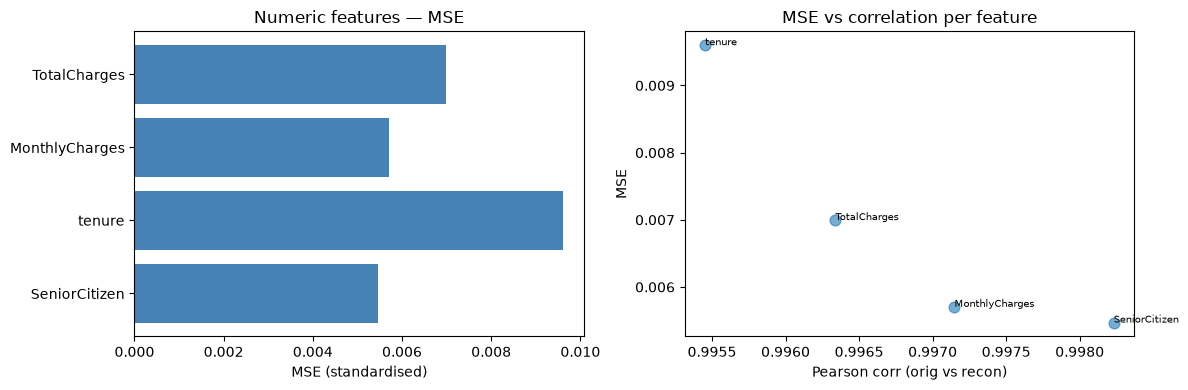

In [10]:
feat_df = evaluator.per_feature_metrics(x_num_test, x_cat_test)
print('Numeric features by MSE (standardised space):')
print(feat_df.sort_values('mse', ascending=False).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.barh(feat_df['feature'], feat_df['mse'], color='steelblue')
ax1.set_xlabel('MSE (standardised)'); ax1.set_title('Numeric features — MSE')
ax2.scatter(feat_df['pearson_corr'], feat_df['mse'], alpha=0.6, s=60)
for _, row in feat_df.iterrows():
    ax2.annotate(row['feature'], (row['pearson_corr'], row['mse']), fontsize=7, ha='left')
ax2.set_xlabel('Pearson corr (orig vs recon)'); ax2.set_ylabel('MSE')
ax2.set_title('MSE vs correlation per feature')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_per_feature_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

### 6a. Categorical accuracy vs baseline (most-frequent)

In [11]:
baseline = evaluator.categorical_baseline(x_cat_test)
ae_acc   = metrics['cat_accuracy']

cat_comparison = pd.DataFrame({
    'feature':      list(baseline.keys()),
    'baseline_acc': list(baseline.values()),
    'ae_acc':       [ae_acc[k] for k in baseline.keys()],
})
cat_comparison['gain'] = cat_comparison['ae_acc'] - cat_comparison['baseline_acc']
print(cat_comparison.sort_values('gain').to_string(index=False))

         feature  baseline_acc   ae_acc     gain
PaperlessBilling      0.594134 0.676443 0.082308
          gender      0.511826 0.604541 0.092715
    PhoneService      0.900662 1.000000 0.099338
      Dependents      0.694418 0.939451 0.245033
  OnlineSecurity      0.482498 0.800378 0.317881
   PaymentMethod      0.214759 0.538316 0.323557
   MultipleLines      0.494797 0.861873 0.367077
        Contract      0.537370 0.905393 0.368023
         Partner      0.504257 0.889309 0.385052
     TechSupport      0.484390 0.875118 0.390728
DeviceProtection      0.424787 0.840114 0.415326
    OnlineBackup      0.355724 0.782403 0.426679
     StreamingTV      0.387890 0.838221 0.450331
 StreamingMovies      0.387890 0.855251 0.467360
 InternetService      0.339640 0.988647 0.649007


## 7. Churn vs Normal — Reconstruction Error Distribution

 class   n  mean_error  median_error
normal 776    0.366764      0.353662
 churn 281    0.359989      0.362668


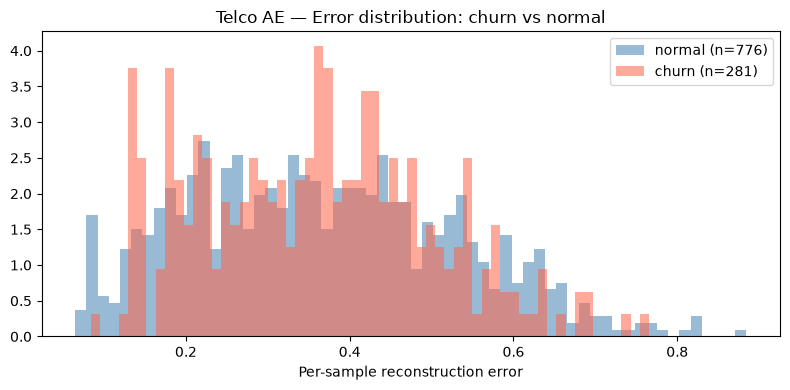

In [12]:
errors = evaluator.per_sample_error(x_num_test, x_cat_test)
class_df = evaluator.metrics_by_class(errors, y_test)
print(class_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
for label, name, color in [(0, 'normal', 'steelblue'), (1, 'churn', 'tomato')]:
    ax.hist(errors[y_test == label], bins=60, alpha=0.55,
            label=f'{name} (n={int((y_test==label).sum()):,})',
            color=color, density=True)
ax.set_xlabel('Per-sample reconstruction error')
ax.set_title('Telco AE — Error distribution: churn vs normal')
ax.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_error_by_class.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Sample Panel — Original vs Reconstructed

In [13]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(x_num_test), size=8, replace=False)

panel = evaluator.sample_panel(
    x_num_test[sample_idx],
    x_cat_test[sample_idx],
    df.iloc[split['test']].iloc[sample_idx].reset_index(drop=True),
)
print('Original vs Reconstructed (transposed):')
print(panel.T.to_string())

Original vs Reconstructed (transposed):
                      original                                                                                                                                                                               reconstructed                                                                                                                                                        
                             0                        1                 2                    3                          4                        5                          6                 7                          0                 1                 2                    3                          4                        5                        6                 7
SeniorCitizen              0.0                      0.0               1.0                  0.0                        0.0                      0.0                        0.0               0.0                        0.0

## 9. Difference Heatmap

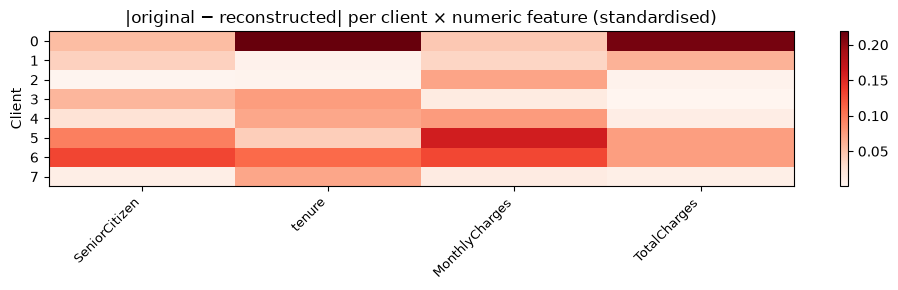

In [14]:
diff = evaluator.difference_matrix(x_num_test[sample_idx], x_cat_test[sample_idx])

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(diff, aspect='auto', cmap='Reds')
ax.set_xticks(range(prep_best.numeric_dim))
ax.set_xticklabels(prep_best.numeric_cols_nc, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Client')
ax.set_yticks(range(8))
ax.set_title('|original − reconstructed| per client × numeric feature (standardised)')
plt.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_difference_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Analysis

**Fill in after running:**

- **Which z_dim and why?** Compare the summary table (Section 4). `z=16` typically balances compression vs quality.
- **Hardest numeric feature?** Likely `TotalCharges` or `tenure` (broader range, higher variance).
- **Churn vs normal gap?** Churned clients tend to have higher reconstruction error — the AE learned only *normal* behaviour, so anomalous patterns reconstruct poorly. This is the foundation for anomaly-based churn detection.
- **Categorical accuracy?** Most binary features (Partner, Dependents, etc.) should be near-perfect. More complex ones (Contract, PaymentMethod) are more informative to track.
- **Heatmap observation?** Identify which numeric features drive most of the reconstruction loss per client.
